<a href="https://colab.research.google.com/github/suba466/Data-analysis/blob/main/Demographic_Data_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget https://raw.githubusercontent.com/freeCodeCamp/boilerplate-medical-data-visualizer/main/medical_examination.csv

--2026-11-16 16:27:26--  https://raw.githubusercontent.com/freeCodeCamp/boilerplate-medical-data-visualizer/main/medical_examination.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2941521 (2.8M) [text/plain]
Saving to: ‘medical_examination.csv’

medical_examination 100%[===================>]   2.80M  --.-KB/s    in 0.05s   

2026-11-16 16:27:27 (53.6 MB/s) - ‘medical_examination.csv’ saved [2941521/2941521]



In [2]:
%%writefile medical_data_visualizer.py
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

#import data
df = pd.read_csv('medical_examination.csv')

#Add 'overweight' column (BMI = weight(kg) / (height(m)^2))
# Height is in cm, so divide by 100 to convert to meters
bmi = df['weight'] / ((df['height'] / 100) ** 2)
df['overweight'] = (bmi > 25).astype(int)

#Normalize data by making 0 always good and 1 always bad
# If value of cholesterol or gluc is 1, set to 0. If > 1, set to 1.
df['cholesterol'] = (df['cholesterol'] > 1).astype(int)
df['gluc'] = (df['gluc'] > 1).astype(int)

#Draw Categorical Plot
def draw_cat_plot():
    #Create DataFrame for cat plot using pd.melt
    df_cat = pd.melt(
        df,
        id_vars=['cardio'],
        value_vars=['cholesterol', 'gluc', 'smoke', 'alco', 'active', 'overweight']
    )

    #Group and reformat data to show counts of each feature split by cardio
    df_cat = df_cat.groupby(['cardio', 'variable', 'value']).size().reset_index(name='total')

    #Draw the catplot using sns.catplot()
    catplot = sns.catplot(
        data=df_cat,
        x='variable',
        y='total',
        hue='value',
        col='cardio',
        kind='bar'
    )

    #Get the figure for the output
    fig = catplot.fig

    #Do not modify the next two lines
    fig.savefig('catplot.png')
    return fig

#Draw Heat Map
def draw_heat_map():
    #Clean the data in df_heat
    df_heat = df[
        (df['ap_lo'] <= df['ap_hi']) &
        (df['height'] >= df['height'].quantile(0.025)) &
        (df['height'] <= df['height'].quantile(0.975)) &
        (df['weight'] >= df['weight'].quantile(0.025)) &
        (df['weight'] <= df['weight'].quantile(0.975))
    ]

    #Calculate the correlation matrix
    corr = df_heat.corr()

    #Generate a mask for the upper triangle
    mask = np.triu(np.ones_like(corr, dtype=bool))

    #Set up the matplotlib figure
    fig, ax = plt.subplots(figsize=(12, 12))

    #Plot the correlation matrix using sns.heatmap()
    sns.heatmap(
        corr,
        annot=True,
        fmt='.1f',
        mask=mask,
        square=True,
        linewidths=0.5,
        cbar_kws={'shrink': 0.5},
        ax=ax
    )

    #Do not modify the next two lines
    fig.savefig('heatmap.png')
    return fig

Writing medical_data_visualizer.py


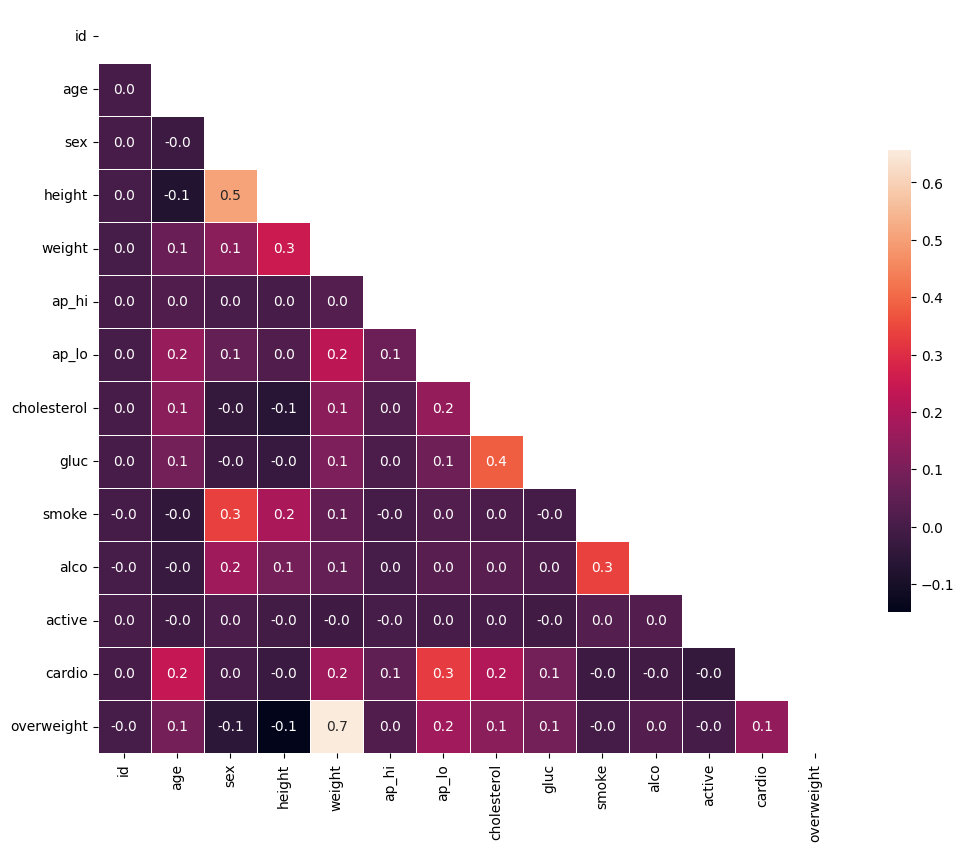

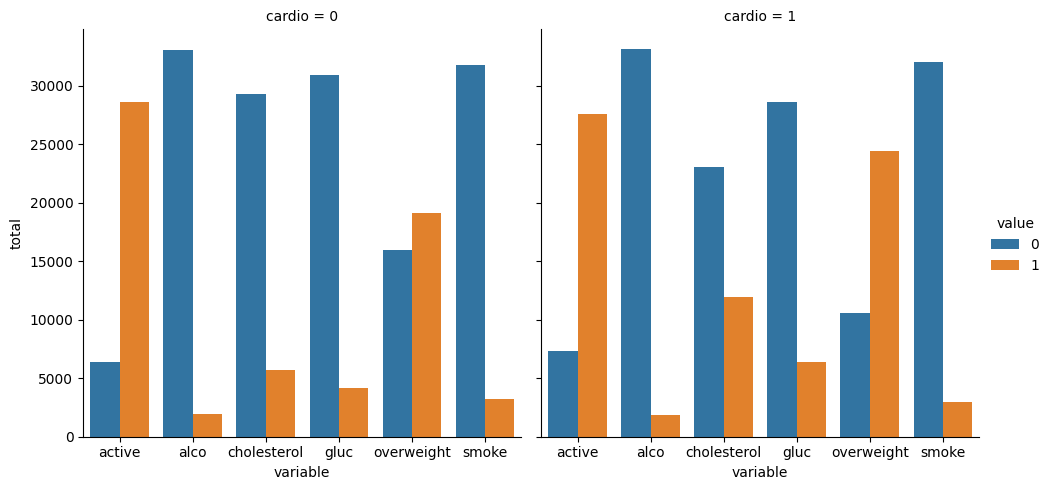

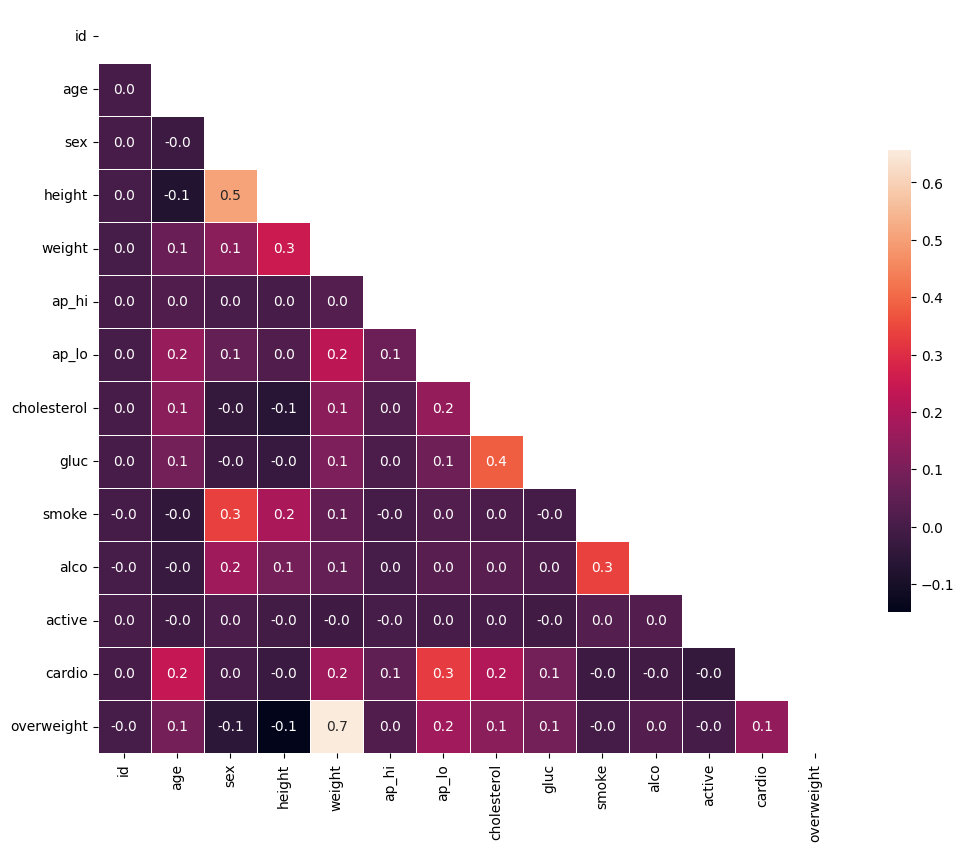

In [3]:
import medical_data_visualizer

# Test Categorical Plot
medical_data_visualizer.draw_cat_plot()

# Test Heat Map
medical_data_visualizer.draw_heat_map()